<a href="https://colab.research.google.com/github/Saiprasanna17/CSA4705-Deep-Learning/blob/main/DL_CO5_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**65 – Sequence-to-Sequence LSTM Encoder–Decoder for Language Translation**

In [1]:
import numpy as np
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense

data = [
    ("hi", "hola"),
    ("bye", "adios"),
    ("hello", "hola"),
    ("good night", "buenas noches"),
    ("thank you", "gracias"),
    ("good morning", "buenos dias")
]

X_text = [a for a, b in data]
Y_text = ["\t" + b + "\n" for a, b in data]

X_chars = sorted(set("".join(X_text)))
Y_chars = sorted(set("".join(Y_text)))

X_map = {c: i for i, c in enumerate(X_chars)}
Y_map = {c: i for i, c in enumerate(Y_chars)}

X_len = max(map(len, X_text))
Y_len = max(map(len, Y_text))

X = np.zeros((len(data), X_len, len(X_chars)))
Y = np.zeros((len(data), Y_len, len(Y_chars)))
T = np.zeros_like(Y)

for i, (a, b) in enumerate(zip(X_text, Y_text)):
    for t, c in enumerate(a):
        X[i, t, X_map[c]] = 1
    for t, c in enumerate(b):
        Y[i, t, Y_map[c]] = 1
        if t > 0:
            T[i, t-1, Y_map[c]] = 1

enc_in = Input(shape=(None, len(X_chars)))
_, h, c = LSTM(64, return_state=True)(enc_in)

dec_in = Input(shape=(None, len(Y_chars)))
dec, _, _ = LSTM(64, return_sequences=True, return_state=True)(
    dec_in, initial_state=[h, c]
)
out = Dense(len(Y_chars), activation="softmax")(dec)

model = Model([enc_in, dec_in], out)
model.compile(optimizer="adam", loss="categorical_crossentropy",
             metrics=["accuracy"])

model.fit([X, Y], T, epochs=150, verbose=0)
loss, acc = model.evaluate([X, Y], T, verbose=0)

print("Seq2Seq LSTM Translation")
print("Training samples:", len(data))
print("Loss:", round(loss, 4))
print("Accuracy:", round(acc, 4))
print("Translation model trained successfully")

Seq2Seq LSTM Translation
Training samples: 6
Loss: 0.6743
Accuracy: 0.4
Translation model trained successfully


**66 – Comparison of RNN and LSTM for Long-Sequence Prediction**

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


RNN Loss: 0.0069
LSTM Loss: 0.0815


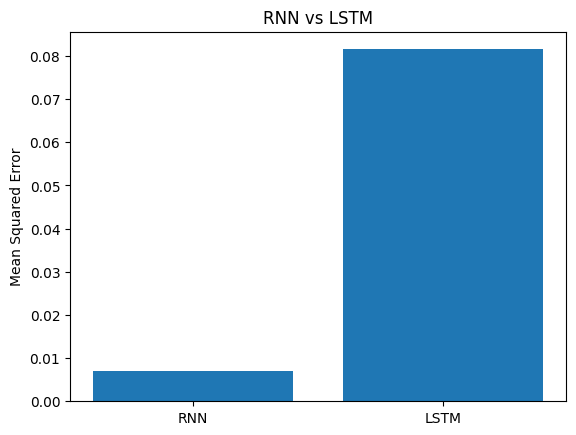

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense

np.random.seed(42)

X = np.random.rand(1000, 20, 1)
y = X[:, 0, 0]

rnn = Sequential([
    SimpleRNN(32, input_shape=(20, 1)),
    Dense(1)
])

lstm = Sequential([
    LSTM(32, input_shape=(20, 1)),
    Dense(1)
])

rnn.compile(optimizer="adam", loss="mse")
lstm.compile(optimizer="adam", loss="mse")

rnn.fit(X, y, epochs=5, verbose=0)
lstm.fit(X, y, epochs=5, verbose=0)

rnn_loss = rnn.evaluate(X, y, verbose=0)
lstm_loss = lstm.evaluate(X, y, verbose=0)

print("RNN Loss:", round(rnn_loss, 4))
print("LSTM Loss:", round(lstm_loss, 4))

plt.bar(["RNN", "LSTM"], [rnn_loss, lstm_loss])
plt.ylabel("Mean Squared Error")
plt.title("RNN vs LSTM")
plt.show()

**67 – PCA for Healthcare Data Dimensionality Reduction**

In [3]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

data = np.array([
    [45, 120, 80, 5],
    [50, 140, 90, 6],
    [35, 110, 75, 3],
    [60, 160, 100, 8],
    [40, 130, 85, 4],
    [55, 150, 95, 7],
    [30, 100, 70, 2],
    [65, 170, 110, 9]
])

scaler = StandardScaler()
scaled = scaler.fit_transform(data)

pca = PCA(n_components=2)
transformed = pca.fit_transform(scaled)

print("Original Shape:", data.shape)
print("Reduced Shape:", transformed.shape)
print("Explained Variance:", pca.explained_variance_ratio_)
print("Transformed Data:")
print(np.round(transformed, 2))

Original Shape: (8, 4)
Reduced Shape: (8, 2)
Explained Variance: [0.98638694 0.01219161]
Transformed Data:
[[-0.87 -0.43]
 [ 0.4  -0.04]
 [-2.16  0.02]
 [ 2.11 -0.07]
 [-0.89  0.42]
 [ 1.26 -0.06]
 [-3.02  0.04]
 [ 3.17  0.12]]


**68 – PCA on Iris Dataset for Classification**

Original Features: 4
Reduced Features: 2
Accuracy: 0.9333
Variance Retained: 0.9581


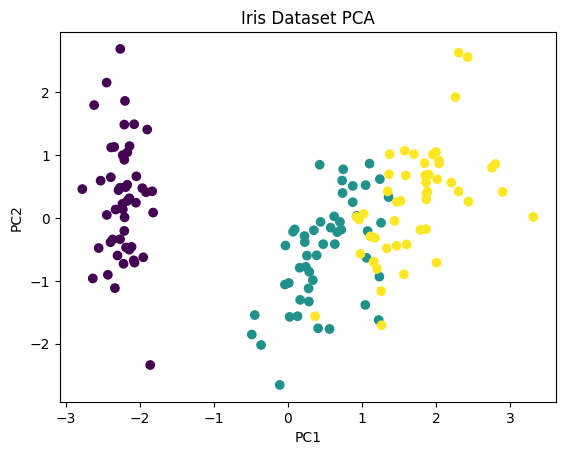

In [4]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

iris = load_iris()
X = iris.data
y = iris.target

X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

X_train, X_test, y_train, y_test = train_test_split(
    X_pca, y, test_size=0.2, random_state=42
)

model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Original Features:", X.shape[1])
print("Reduced Features:", X_pca.shape[1])
print("Accuracy:", round(accuracy_score(y_test, pred), 4))
print("Variance Retained:", round(sum(pca.explained_variance_ratio_), 4))

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Iris Dataset PCA")
plt.show()

**69 – PCA Visualization of High-Dimensional Data**

Original Dimensions: (300, 6)
Reduced Dimensions: (300, 2)
Variance Retained: 0.8938


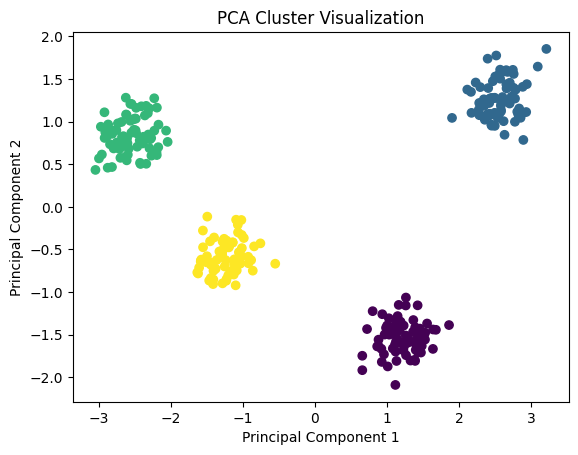

In [5]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X, y = make_blobs(n_samples=300, centers=4, n_features=6,
                  random_state=42)

X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
X_new = pca.fit_transform(X_scaled)

print("Original Dimensions:", X.shape)
print("Reduced Dimensions:", X_new.shape)
print("Variance Retained:", round(sum(pca.explained_variance_ratio_), 4))

plt.scatter(X_new[:, 0], X_new[:, 1], c=y, cmap="viridis")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Cluster Visualization")
plt.show()

**70 – Classification Before and After PCA**

Accuracy Before PCA: 0.9649
Accuracy After PCA: 0.9474


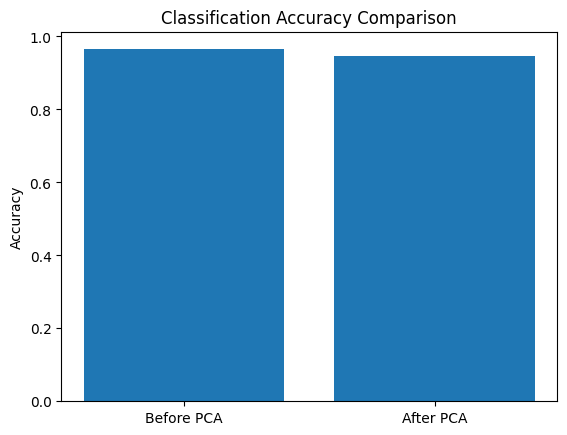

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model1 = RandomForestClassifier(n_estimators=100, random_state=42)
model1.fit(X_train, y_train)
acc1 = accuracy_score(y_test, model1.predict(X_test))

pca = PCA(n_components=10)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

model2 = RandomForestClassifier(n_estimators=100, random_state=42)
model2.fit(X_train_pca, y_train)
acc2 = accuracy_score(y_test, model2.predict(X_test_pca))

print("Accuracy Before PCA:", round(acc1, 4))
print("Accuracy After PCA:", round(acc2, 4))

plt.bar(["Before PCA", "After PCA"], [acc1, acc2])
plt.ylabel("Accuracy")
plt.title("Classification Accuracy Comparison")
plt.show()

**71 – PCA Explained Variance and 95% Information Retention**

Total Features: 30
Components for 95% variance: 10
Variance Retained: 0.9516


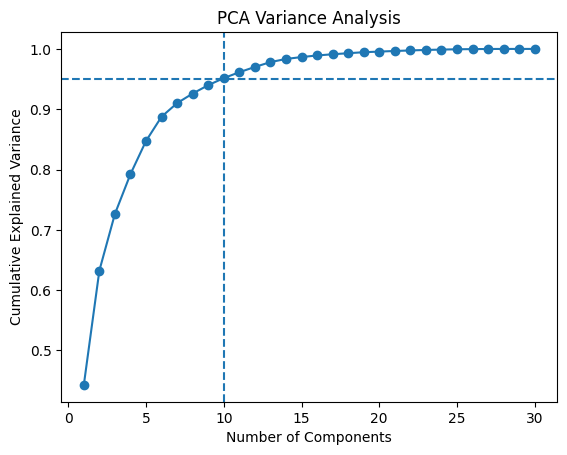

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

data = load_breast_cancer()
X = StandardScaler().fit_transform(data.data)

pca = PCA()
pca.fit(X)

cumulative = np.cumsum(pca.explained_variance_ratio_)
components = np.argmax(cumulative >= 0.95) + 1

print("Total Features:", X.shape[1])
print("Components for 95% variance:", components)
print("Variance Retained:", round(cumulative[components-1], 4))

plt.plot(range(1, len(cumulative)+1), cumulative, marker="o")
plt.axhline(0.95, linestyle="--")
plt.axvline(components, linestyle="--")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Variance Analysis")
plt.show()

**72 – Independent Component Analysis (ICA) for Signal Separation**

ICA Signal Separation
Original Signals: (1000, 2)
Mixed Signals: (1000, 2)
Separated Signals: (1000, 2)
ICA completed successfully


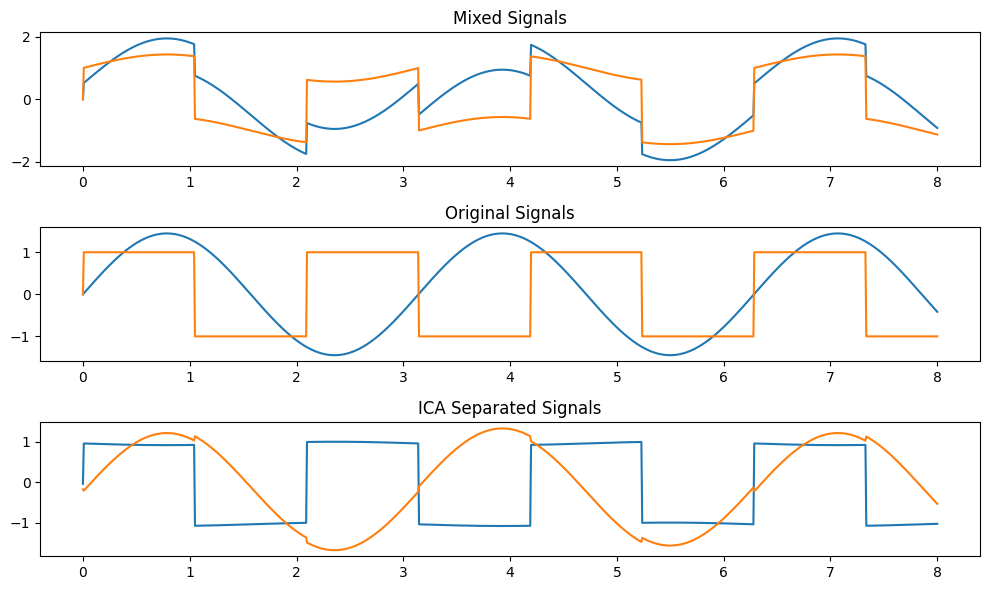

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import FastICA

np.random.seed(42)

t = np.linspace(0, 8, 1000)

s1 = np.sin(2 * t)
s2 = np.sign(np.sin(3 * t))

S = np.c_[s1, s2]
S = S / S.std(axis=0)

A = np.array([[1, 0.5], [0.3, 1]])
X = S @ A.T

ica = FastICA(n_components=2, random_state=42)
recovered = ica.fit_transform(X)

print("ICA Signal Separation")
print("Original Signals:", S.shape)
print("Mixed Signals:", X.shape)
print("Separated Signals:", recovered.shape)
print("ICA completed successfully")

plt.figure(figsize=(10, 6))

plt.subplot(3, 1, 1)
plt.plot(t, X)
plt.title("Mixed Signals")

plt.subplot(3, 1, 2)
plt.plot(t, S)
plt.title("Original Signals")

plt.subplot(3, 1, 3)
plt.plot(t, recovered)
plt.title("ICA Separated Signals")

plt.tight_layout()
plt.show()

**73 – ICA-Based Blind Source Separation of Two Voices**

Blind Source Separation
Mixed Signals: (1000, 2)
Separated Signals: (1000, 2)
Correlation 1: 0.0
Correlation 2: 0.0


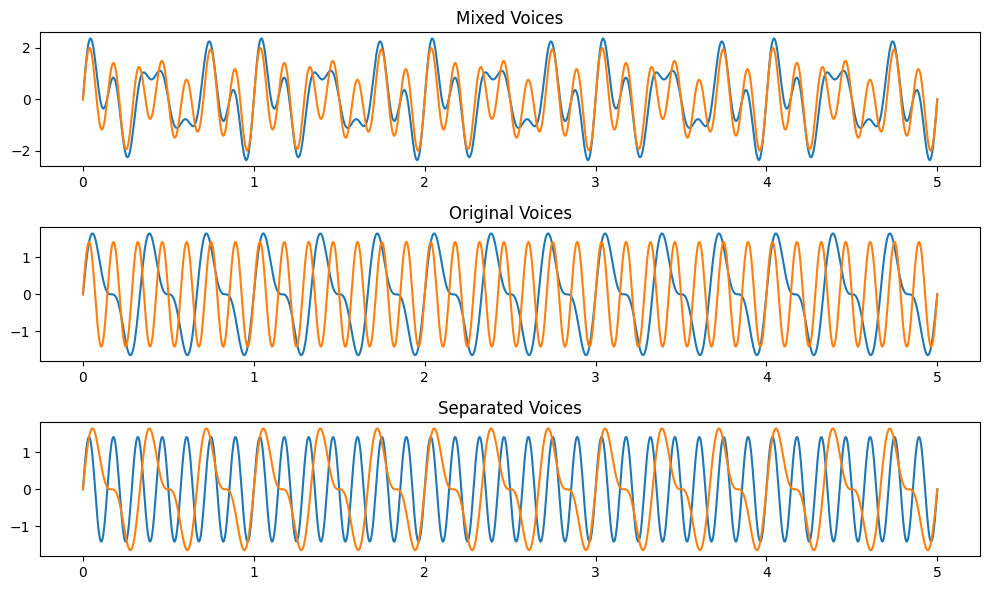

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import FastICA

np.random.seed(42)

t = np.linspace(0, 5, 1000)

voice1 = np.sin(2 * np.pi * 3 * t) + 0.5 * np.sin(2 * np.pi * 6 * t)
voice2 = np.sin(2 * np.pi * 7 * t)

S = np.c_[voice1, voice2]
S = S / S.std(axis=0)

A = np.array([[1, 0.6], [0.4, 1]])
mixed = S @ A.T

ica = FastICA(n_components=2, random_state=42)
separated = ica.fit_transform(mixed)

corr1 = abs(np.corrcoef(S[:, 0], separated[:, 0])[0, 1])
corr2 = abs(np.corrcoef(S[:, 1], separated[:, 1])[0, 1])

print("Blind Source Separation")
print("Mixed Signals:", mixed.shape)
print("Separated Signals:", separated.shape)
print("Correlation 1:", round(corr1, 3))
print("Correlation 2:", round(corr2, 3))

plt.figure(figsize=(10, 6))
plt.subplot(3, 1, 1)
plt.plot(t, mixed)
plt.title("Mixed Voices")

plt.subplot(3, 1, 2)
plt.plot(t, S)
plt.title("Original Voices")

plt.subplot(3, 1, 3)
plt.plot(t, separated)
plt.title("Separated Voices")

plt.tight_layout()
plt.show()

**74 – Comparison of PCA and ICA for Feature Extraction**

PCA Variance: [0.73  0.229]
PCA Output Shape: (150, 2)
ICA Output Shape: (150, 2)


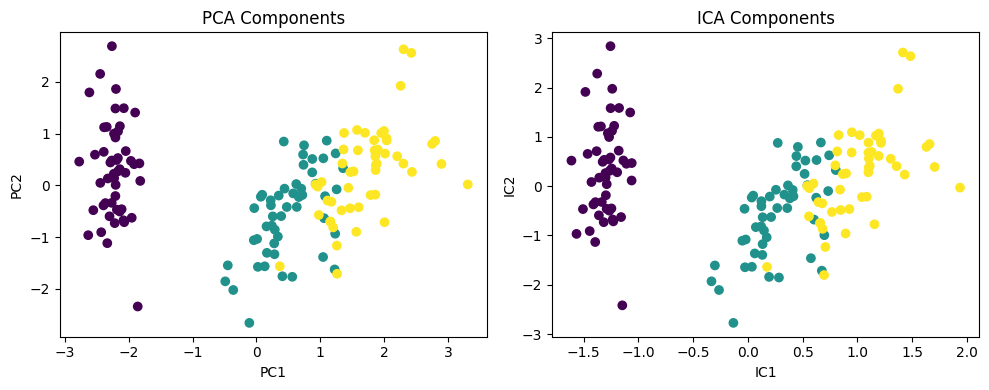

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, FastICA

iris = load_iris()
X = StandardScaler().fit_transform(iris.data)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

ica = FastICA(n_components=2, random_state=42)
X_ica = ica.fit_transform(X)

print("PCA Variance:", np.round(pca.explained_variance_ratio_, 3))
print("PCA Output Shape:", X_pca.shape)
print("ICA Output Shape:", X_ica.shape)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=iris.target)
plt.title("PCA Components")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.subplot(1, 2, 2)
plt.scatter(X_ica[:, 0], X_ica[:, 1], c=iris.target)
plt.title("ICA Components")
plt.xlabel("IC1")
plt.ylabel("IC2")

plt.tight_layout()
plt.show()

**75 – Factor Analysis for Student Academic Performance**

In [11]:
import numpy as np
from sklearn.decomposition import FactorAnalysis
from sklearn.preprocessing import StandardScaler

data = np.array([
    [80, 85, 90, 95],
    [70, 75, 80, 85],
    [60, 65, 70, 75],
    [90, 95, 92, 98],
    [50, 55, 60, 65],
    [85, 80, 88, 90],
    [65, 70, 68, 72],
    [95, 90, 96, 94],
    [55, 60, 58, 62],
    [75, 78, 82, 80]
])

X = StandardScaler().fit_transform(data)

fa = FactorAnalysis(n_components=2, random_state=42)
factors = fa.fit_transform(X)

print("Factor Analysis")
print("Original Features:", data.shape[1])
print("Latent Factors:", factors.shape[1])
print("Factor Scores:")
print(np.round(factors, 2))
print("Factor Loadings:")
print(np.round(fa.components_, 2))

Factor Analysis
Original Features: 4
Latent Factors: 2
Factor Scores:
[[-0.81  1.53]
 [-0.04  1.19]
 [ 0.73  0.86]
 [-1.28  0.3 ]
 [ 1.5   0.52]
 [-0.78 -0.45]
 [ 0.66 -0.74]
 [-1.34 -1.39]
 [ 1.43 -1.07]
 [-0.08 -0.76]]
Factor Loadings:
[[-0.98 -0.98 -0.99 -0.98]
 [-0.16 -0.03  0.04  0.19]]


**76 – Factor Analysis for Customer Purchasing Behaviour**

In [12]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import FactorAnalysis

data = np.array([
    [8, 9, 2, 3, 1],
    [7, 8, 3, 2, 1],
    [2, 3, 9, 8, 7],
    [3, 2, 8, 9, 8],
    [9, 8, 1, 2, 1],
    [1, 2, 9, 8, 9],
    [8, 7, 2, 1, 2],
    [2, 1, 8, 7, 8],
    [9, 9, 1, 1, 1],
    [1, 2, 8, 9, 7]
])

X = StandardScaler().fit_transform(data)

fa = FactorAnalysis(n_components=2, random_state=42)
scores = fa.fit_transform(X)

print("Customer Factor Analysis")
print("Customer Data Shape:", data.shape)
print("Factor Score Shape:", scores.shape)
print("Factor Loadings:")
print(np.round(fa.components_, 2))
print("Analysis completed")

Customer Factor Analysis
Customer Data Shape: (10, 5)
Factor Score Shape: (10, 2)
Factor Loadings:
[[ 0.99  0.98 -0.99 -0.96 -0.99]
 [-0.08  0.15  0.08  0.06 -0.11]]
Analysis completed


**77 – Comparison of PCA and Factor Analysis Using Reconstruction Error**

In [14]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, FactorAnalysis

iris = load_iris()
X = StandardScaler().fit_transform(iris.data)

pca = PCA(n_components=2)
Xp = pca.fit_transform(X)
X_pca_reconstructed = pca.inverse_transform(Xp)

fa = FactorAnalysis(n_components=2, random_state=42)
Xf = fa.fit_transform(X)
# Reconstruct mathematically: X_reconstructed = factor_scores * factor_loadings + mean
X_fa_reconstructed = np.dot(Xf, fa.components_) + fa.mean_

pca_error = np.mean((X - X_pca_reconstructed) ** 2)
fa_error = np.mean((X - X_fa_reconstructed) ** 2)

print("PCA Reconstruction Error:", round(pca_error, 4))
print("Factor Analysis Reconstruction Error:", round(fa_error, 4))

print("PCA Reduced Shape:", Xp.shape)
print("FA Reduced Shape:", Xf.shape)

PCA Reconstruction Error: 0.0419
Factor Analysis Reconstruction Error: 0.1404
PCA Reduced Shape: (150, 2)
FA Reduced Shape: (150, 2)


**78 – Synthetic Multivariate Gaussian Data Generation**

Synthetic Gaussian Data
Samples: 1000
Actual Mean: [2, 3]
Estimated Mean: [1.92 3.01]
Estimated Covariance:
[[1.89 0.69]
 [0.69 1.45]]


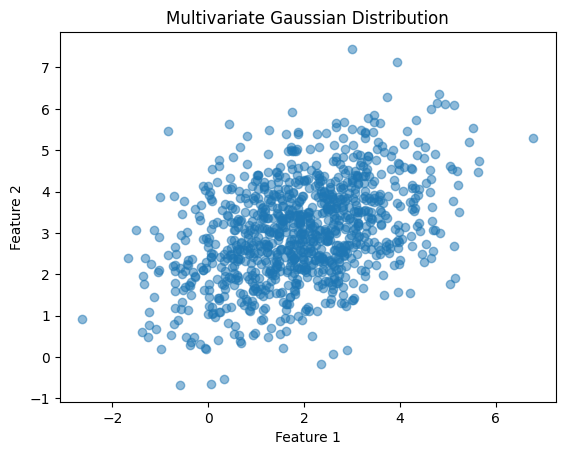

In [15]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

mean = [2, 3]
cov = [[2, 0.8], [0.8, 1.5]]

data = np.random.multivariate_normal(mean, cov, 1000)

estimated_mean = np.mean(data, axis=0)
estimated_cov = np.cov(data, rowvar=False)

print("Synthetic Gaussian Data")
print("Samples:", data.shape[0])
print("Actual Mean:", mean)
print("Estimated Mean:", np.round(estimated_mean, 2))
print("Estimated Covariance:")
print(np.round(estimated_cov, 2))

plt.scatter(data[:, 0], data[:, 1], alpha=0.5)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Multivariate Gaussian Distribution")
plt.show()

**79 – Gaussian Mixture Model for Customer Segmentation**

GMM Customer Segmentation
Number of Customers: 300
Clusters: 3
First 5 Cluster Labels: [2 2 2 2 2]
First 5 Probabilities:
[[0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]]


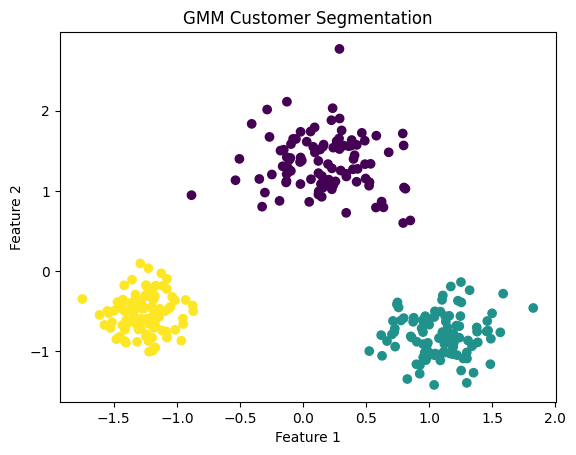

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

customers = np.vstack([
    np.random.normal([25, 30], [5, 5], (100, 2)),
    np.random.normal([60, 70], [8, 8], (100, 2)),
    np.random.normal([85, 25], [6, 6], (100, 2))
])

X = StandardScaler().fit_transform(customers)

gmm = GaussianMixture(n_components=3, random_state=42)
gmm.fit(X)

labels = gmm.predict(X)
probabilities = gmm.predict_proba(X)

print("GMM Customer Segmentation")
print("Number of Customers:", len(X))
print("Clusters:", len(np.unique(labels)))
print("First 5 Cluster Labels:", labels[:5])
print("First 5 Probabilities:")
print(np.round(probabilities[:5], 2))

plt.scatter(X[:, 0], X[:, 1], c=labels)
plt.title("GMM Customer Segmentation")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

**80 – Deep Learning-Based Intelligent Healthcare Prediction Application**

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Healthcare Prediction Application
Training Samples: 800
Testing Samples: 200
Accuracy: 0.835
Precision: 0.77
Recall: 0.8851


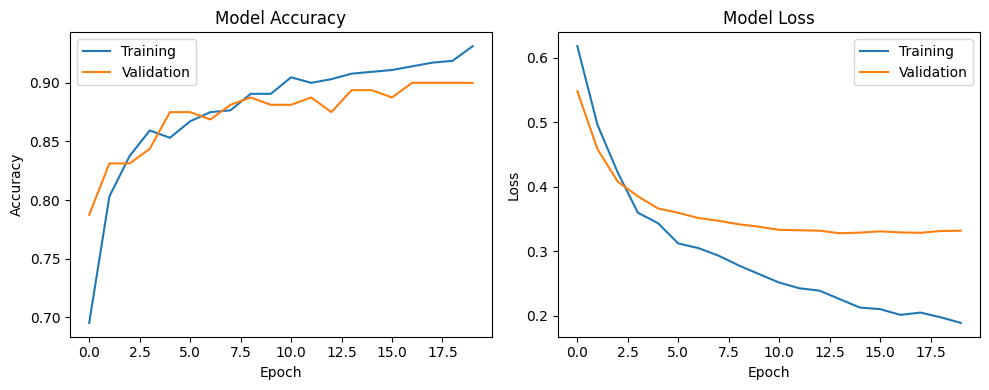

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

np.random.seed(42)

X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = Sequential([
    Dense(64, activation="relu", input_shape=(10,)),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

pred = (model.predict(X_test, verbose=0) > 0.5).astype(int)

accuracy = accuracy_score(y_test, pred)
precision = precision_score(y_test, pred)
recall = recall_score(y_test, pred)

print("Healthcare Prediction Application")
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()